# Chapter 1 · σ-algebras: interactive demos

Companion to Chapter 1 of the notes [*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you change the inputs.
The widgets need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/01-sigma-algebras.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, Text, SelectMultiple, Dropdown, Checkbox

from probnotes.sigma import (atoms, atoms_from_matrix, bell, borel_generator_traces, check_axioms,
                             closure_steps, count_algebras_bruteforce, generate, interval_complement,
                             interval_union, membership_matrix, BOREL_FAMILIES)
from probnotes.style import COBALT, GOLD, GREY, INK, PALETTE, use_style

use_style()
ATOM_COLORS = PALETTE + ["#8A6D3B", "#3B8A86", "#B0479A", "#7A7A7A", "#C9A227"]


def fmt(S):
    """A set of numbers as a short string, e.g. {1, 2}; the empty set as ∅."""
    return "∅" if not S else "{" + ", ".join(str(x) for x in sorted(S)) + "}"


def parse_family(text, n):
    """'1,2; 2,3' -> [{1, 2}, {2, 3}]; points outside {1, ..., n} are dropped."""
    fam = []
    for chunk in text.split(";"):
        pts = {int(t) for t in chunk.replace("{", "").replace("}", "").split(",") if t.strip()}
        if chunk.strip():
            fam.append({x for x in pts if 1 <= x <= n})
    return fam

## 1. Building $\sigma(\mathcal E)$ on a finite set

Type a family $\mathcal E$ of subsets of $X=\{1,\dots,n\}$, sets separated by semicolons. The top panel shows which
points lie in which set; points with the same pattern (the same column) form an **atom**, drawn in one colour in the
bottom row. $\sigma(\mathcal E)$ is the set of all unions of atoms, so it has $2^k$ elements for $k$ atoms
(Remark 1.14 of the notes).

The same σ-algebra is also built by brute force: start from $\mathcal E\cup\{X\}$ and add complements and unions of
two sets until nothing changes. The sizes of the successive families are printed; the two methods always agree.

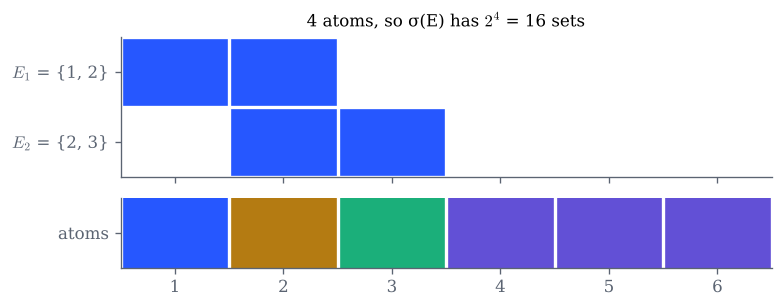

atoms: {1}, {2}, {3}, {4, 5, 6}
closure algorithm, sizes of the successive families: [3, 7, 11, 14, 16]
σ(E) = ∅, {1}, {2}, {3}, {1, 2}, {1, 3}, {2, 3}, {1, 2, 3}, {4, 5, 6}, {1, 4, 5, 6}, {2, 4, 5, 6}, {3, 4, 5, 6}, {1, 2, 4, 5, 6}, {1, 3, 4, 5, 6}, {2, 3, 4, 5, 6}, {1, 2, 3, 4, 5, 6}


In [2]:
def show_sigma(n=6, family="1,2; 2,3"):
    X = list(range(1, n + 1))
    E = parse_family(family, n)
    at = atoms(E, X)
    steps = closure_steps(E, X)
    S = generate(E, X)
    assert S == steps[-1]
    M = membership_matrix(E, X)
    label = np.zeros(n, dtype=int)
    for j, a in enumerate(at):
        label[[x - 1 for x in a]] = j
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(7, 0.45 * len(E) + 1.6), sharex=True,
                                  gridspec_kw={"height_ratios": [max(len(E), 1), 1]})
    ax.imshow(M if len(E) else np.zeros((1, n)), cmap=plt.matplotlib.colors.ListedColormap(["white", COBALT]),
              vmin=0, vmax=1, aspect="auto")
    ax.set_yticks(range(len(E)), [f"$E_{{{j+1}}}$ = {fmt(e)}" for j, e in enumerate(E)] if E else [])
    ax.set_title(f"{len(at)} atoms, so σ(E) has $2^{{{len(at)}}}$ = {len(S)} sets")
    colors = [ATOM_COLORS[j % len(ATOM_COLORS)] for j in range(len(at))]
    ax2.imshow(label[None, :], cmap=plt.matplotlib.colors.ListedColormap(colors), vmin=-0.5,
               vmax=len(at) - 0.5, aspect="auto")
    ax2.set_yticks([0], ["atoms"])
    ax2.set_xticks(range(n), X)
    for a in (ax, ax2):
        a.grid(False)
        a.set_xticks(np.arange(-0.5, n), minor=True)
        a.tick_params(which="minor", length=0)
        a.grid(which="minor", color="white", lw=2)
    ax.set_yticks(np.arange(-0.5, max(len(E), 1)), minor=True)
    plt.show()
    print("atoms:", ", ".join(fmt(a) for a in at))
    print("closure algorithm, sizes of the successive families:", [len(s) for s in steps])
    if len(S) <= 32:
        print("σ(E) =", ", ".join(fmt(s) for s in sorted(S, key=lambda s: (len(s), sorted(s)))))

show_sigma()

In [3]:
# Explore: try "1,2,3; 3,4,5; 5,6,1" (it separates points), "1,2; 3,4; 5,6", or the empty family "".
interact(show_sigma,
         n=IntSlider(value=6, min=1, max=10, continuous_update=False, description="n"),
         family=Text(value="1,2; 2,3", continuous_update=False, description="E"));

## 2. Checking the axioms of an algebra

The examples of the notes on $X=\{1,2,3\}$: $\{X,\{1\},\{2\},\{3\}\}$ is not an algebra,
$\{X,\emptyset,\{1\},\{2,3\}\}$ is. The union of the two σ-algebras $\mathcal A_1=\{X,\emptyset,\{1\},\{2,3\}\}$
and $\mathcal A_2=\{X,\emptyset,\{1,2\},\{3\}\}$ is not an algebra (Remark 1.11), and the σ-algebra it generates,
$\mathcal A_1\vee\mathcal A_2$, is the whole power set.

In [4]:
X3 = [1, 2, 3]

def report(F, X=X3, name=""):
    r = check_axioms(F, X)
    verdict = "an algebra" if (r["contains_X"] and r["complements"] is None and r["unions"] is None) else "NOT an algebra"
    print(f"{name}{{" + ", ".join(fmt(s) for s in F) + "}  ->  " + verdict)
    if not r["contains_X"]:
        print("    X is missing")
    if r["complements"] is not None:
        A = r["complements"]
        print(f"    the complement of {fmt(A)}, {fmt(set(X) - A)}, is missing")
    if r["unions"] is not None:
        A, B = r["unions"]
        print(f"    the union of {fmt(A)} and {fmt(B)}, {fmt(A | B)}, is missing")

report([X3, {1}, {2}, {3}])
report([X3, set(), {1}, {2, 3}])
A1 = [X3, set(), {1}, {2, 3}]
A2 = [X3, set(), {1, 2}, {3}]
report(sorted({frozenset(s) for s in A1 + A2}, key=lambda s: (len(s), sorted(s))), name="A1 ∪ A2 = ")
print("A1 ∨ A2 has", len(generate(A1 + A2, X3)), "sets: the power set of X")

{{1, 2, 3}, {1}, {2}, {3}}  ->  NOT an algebra
    the complement of {1}, {2, 3}, is missing
    the union of {1} and {2}, {1, 2}, is missing
{{1, 2, 3}, ∅, {1}, {2, 3}}  ->  an algebra
A1 ∪ A2 = {∅, {1}, {3}, {1, 2}, {2, 3}, {1, 2, 3}}  ->  NOT an algebra
    the union of {1} and {3}, {1, 3}, is missing
A1 ∨ A2 has 8 sets: the power set of X


In [5]:
# Explore: pick any family of subsets of {1, 2, 3} (ctrl/cmd-click to select several).
subsets = sorted(generate([{1}, {2}, {3}], X3), key=lambda s: (len(s), sorted(s)))

def pick(family=(fmt({1, 2, 3}), fmt({1}))):
    F = [s for s in subsets if fmt(s) in family]
    report(F)
    print("the σ-algebra it generates:", "{" + ", ".join(fmt(s) for s in sorted(generate(F, X3), key=lambda s: (len(s), sorted(s)))) + "}")

interact(pick, family=SelectMultiple(options=[fmt(s) for s in subsets], value=(fmt({1, 2, 3}), fmt({1})),
                                     rows=8, description="family"));

## 3. How many σ-algebras?

On a finite set, a σ-algebra is determined by its atoms, which form a partition of the set. So the number of
σ-algebras on an $n$-point set is the number of its partitions, the Bell number $B_n$. For $n\le4$ this can be
checked by brute force over all $2^{2^n}$ families of subsets; the plot compares the two counts, on a logarithmic
scale. Very few families are σ-algebras.

brute force, n = 1..4: [1, 2, 5, 15]
Bell numbers, n = 1..8: [1, 2, 5, 15, 52, 203, 877, 4140]


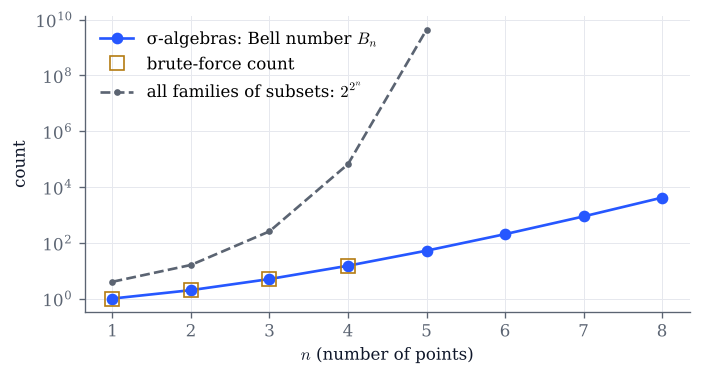

In [6]:
ns = np.arange(1, 9)
brute = [count_algebras_bruteforce(n) for n in range(1, 5)]
print("brute force, n = 1..4:", brute)
print("Bell numbers, n = 1..8:", [bell(n) for n in ns])
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(ns, [bell(n) for n in ns], color=COBALT, marker="o", label="σ-algebras: Bell number $B_n$")
ax.plot(ns[:4], brute, color=GOLD, marker="s", ls="", ms=8, mfc="none", label="brute-force count")
ax.plot(ns[:5], [2.0 ** (2 ** n) for n in ns[:5]], color=GREY, marker=".", ls="--",
        label="all families of subsets: $2^{2^n}$")
ax.set(yscale="log", xlabel="$n$ (number of points)", ylabel="count")
ax.legend()
plt.show()

## 4. The algebra of finite unions of intervals $[a,b)$

Example 1.8 of the notes: on $X=[0,1)$ the finite unions of disjoint intervals $[a,b)$ form an algebra. Unions and
complements of such sets are again of the same form; the code puts them in canonical form (disjoint, sorted,
touching intervals merged). Type two sets as lists of intervals `a-b`.

The algebra is not a σ-algebra: the union of $[\frac1n,1)$ over $n\le N$ is $[\frac1N,1)$, which always contains its
left endpoint, while the union over all $n$ is $(0,1)$, which is not in the algebra.

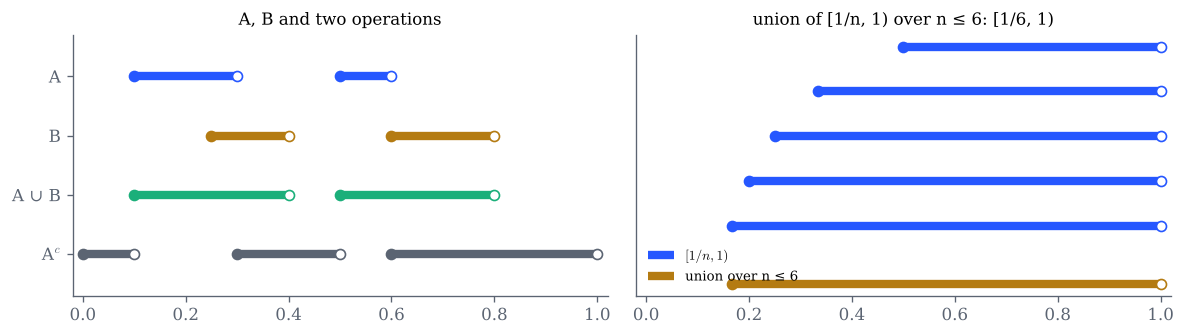

A ∪ B = [(0.1, 0.4), (0.5, 0.8)]    A^c = [(0, 0.1), (0.3, 0.5), (0.6, 1)]


In [7]:
def parse_intervals(text):
    out = []
    for chunk in text.split(","):
        if "-" in chunk:
            a, b = (float(t) for t in chunk.split("-"))
            out.append((min(max(a, 0.0), 1.0), min(max(b, 0.0), 1.0)))
    return out


def draw(ax, ivs, y, color, label):
    for k, (a, b) in enumerate(ivs):
        ax.plot([a, b], [y, y], color=color, lw=5, solid_capstyle="butt", label=label if k == 0 else None)
        ax.plot([a], [y], "o", color=color, ms=6)
        ax.plot([b], [y], "o", color=color, mfc="white", ms=6)


def interval_algebra(A="0.1-0.3, 0.5-0.6", B="0.25-0.4, 0.6-0.8", N=6):
    A, B = interval_union(parse_intervals(A)), interval_union(parse_intervals(B))
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 2.9))
    rows = [("A", A, COBALT), ("B", B, GOLD), ("A ∪ B", interval_union(A, B), PALETTE[2]),
            ("A$^c$", interval_complement(A), GREY)]
    for k, (name, ivs, color) in enumerate(rows):
        draw(ax, ivs, len(rows) - k, color, name)
    ax.set(xlim=(-0.02, 1.02), ylim=(0.3, len(rows) + 0.7), yticks=range(len(rows), 0, -1),
           title="A, B and two operations")
    ax.set_yticklabels([r[0] for r in rows])
    for n in range(1, N + 1):
        draw(ax2, interval_union([(1 / n, 1.0)]), N - n + 2, COBALT, "$[1/n,1)$" if n == 2 else None)
    U = interval_union(*[[(1 / n, 1.0)] for n in range(1, N + 1)])
    draw(ax2, U, 0.7, GOLD, f"union over n ≤ {N}")
    ax2.set(xlim=(-0.02, 1.02), yticks=[],
            title=f"union of [1/n, 1) over n ≤ {N}: " + ("∅" if not U else f"[1/{N}, 1)"))
    if N >= 2:
        ax2.legend(loc="lower left", fontsize=8)
    for a in (ax, ax2):
        a.grid(False)
    fig.tight_layout()
    plt.show()
    print("A ∪ B =", interval_union(A, B), "   A^c =", interval_complement(A))

interval_algebra()

In [8]:
interact(interval_algebra,
         A=Text(value="0.1-0.3, 0.5-0.6", continuous_update=False, description="A"),
         B=Text(value="0.25-0.4, 0.6-0.8", continuous_update=False, description="B"),
         N=IntSlider(value=6, min=1, max=40, continuous_update=False, description="N"));

## 5. The generators of $\mathcal B(\mathbb R)$ on a finite grid

Proposition 1.18: the eight families $\mathcal E_1=\{(a,b)\}$, …, $\mathcal E_8=\{[a,+\infty)\}$ all generate
$\mathcal B(\mathbb R)$. The proof moves endpoints, as in $(a,b)=\bigcup_n(a,b-\frac1n]$. Here only finitely many
endpoints are allowed, the multiples of $1/M$ in $[0,1]$ (optionally one more step on each side), and the sets
are traced on the grid $\{k/N\}$. Each colour is an atom of the σ-algebra generated on the grid. With few endpoints the
eight families give different σ-algebras.

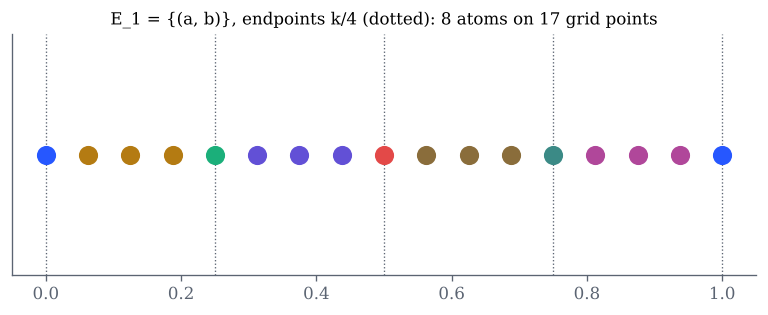

number of atoms for E_1, ..., E_8: [8, 5, 5, 7, 5, 5, 5, 5]


In [9]:
def grid_atoms(i=1, N=16, M=4, extend=False):
    grid = np.arange(N + 1) / N
    ends = np.arange(-1 if extend else 0, M + (2 if extend else 1)) / M
    fig, ax = plt.subplots(figsize=(8, 2.6))
    counts = []
    for j in range(1, 9):
        at = atoms_from_matrix(borel_generator_traces(j, grid, ends), list(grid))
        counts.append(len(at))
        if j != i:
            continue
        for k, a in enumerate(at):
            xs = sorted(a)
            ax.scatter(xs, [0] * len(xs), s=110, color=ATOM_COLORS[k % len(ATOM_COLORS)], zorder=3)
    for e in ends:
        ax.axvline(e, color=GREY, lw=0.8, ls=":")
    ax.set(xlim=(ends.min() - 0.05, ends.max() + 0.05), ylim=(-1, 1), yticks=[],
           title=f"E_{i} = {{{BOREL_FAMILIES[i]}}}, endpoints k/{M} (dotted): {counts[i - 1]} atoms on {N + 1} grid points")
    ax.grid(False)
    plt.show()
    print("number of atoms for E_1, ..., E_8:", counts)

grid_atoms()

In [10]:
# Explore: which families give the same σ-algebra? What changes when the endpoints extend beyond [0, 1]?
interact(grid_atoms,
         i=Dropdown(options=list(range(1, 9)), value=1, description="family i"),
         N=IntSlider(value=16, min=2, max=48, continuous_update=False, description="grid N"),
         M=IntSlider(value=4, min=1, max=48, continuous_update=False, description="endpoints M"),
         extend=Checkbox(value=False, description="extend beyond [0,1]"));

## Things to try

- In section 1, find a family of three sets that generates the whole power set of $\{1,\dots,8\}$. Why can no family of
  two sets do it?
- In section 1, how many rounds does the closure algorithm need? Can you find a family that needs many?
- In section 5, take $M=N$. Which family still fails to give the power set of the grid, and why does ticking
  *extend beyond [0,1]* fix it?